# Titanic — ex2

## 1. Practice Overview
Bài thực hành so sánh Logistic Regression, LinearSVC và Random Forest trên dữ liệu Titanic.
Mục tiêu: thực hiện đầy đủ quy trình phân loại, đánh giá và phân tích lỗi.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

RANDOM_STATE = 42


## 2. Problem Definition
- Bài toán: Binary Classification.
- Target: `Survived`, với `0` = không sống sót, `1` = sống sót.
- Features: `Pclass`, `Sex`, `Age`, `SibSp`, `Parch`, `Fare`, `Embarked`.
- Tiêu chí chọn model: F1 trung bình cao nhất trên 5-fold CV của Train.

F1 cân bằng precision và recall của lớp sống sót. Accuracy, precision, recall
vẫn được báo cáo để nhìn rõ các loại lỗi. Không chọn model bằng điểm Test.


## 3. Dataset Understanding


In [2]:
df = pd.read_csv("titanic.csv")
print("Rows, columns:", df.shape)
print("Columns:", df.columns.tolist())
df.head()


Rows, columns: (891, 12)
Columns: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 4. Quick Data Check
Kiểm tra giá trị thiếu, dòng trùng, kiểu dữ liệu và tỷ lệ từng nhãn.
Các số dưới đây được tính từ file thực tế.


In [3]:
data_check = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_percent": df.isna().mean() * 100
})
print(data_check.to_string())
print("\nDuplicates:", df.duplicated().sum())
print("\nTarget counts:")
print(df["Survived"].value_counts())
print("\nTarget proportions:")
print(df["Survived"].value_counts(normalize=True))


               dtype  missing  missing_percent
PassengerId    int64        0         0.000000
Survived       int64        0         0.000000
Pclass         int64        0         0.000000
Name             str        0         0.000000
Sex              str        0         0.000000
Age          float64      177        19.865320
SibSp          int64        0         0.000000
Parch          int64        0         0.000000
Ticket           str        0         0.000000
Fare         float64        0         0.000000
Cabin            str      687        77.104377
Embarked         str        2         0.224467

Duplicates: 0

Target counts:
Survived
0    549
1    342
Name: count, dtype: int64

Target proportions:
Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64


## 5. Simple Data Preparation
Loại dòng trùng, chọn features và tách X/y, sau đó thực hiện trực tiếp:
điền missing values, one-hot encoding và scaling trước khi chia Train/Test.
`PassengerId`, `Name`, `Ticket` được bỏ; `Cabin` được bỏ vì tỷ lệ thiếu cao.

Lưu ý: median/mode và scaler ở đây học từ toàn bộ dữ liệu. Cách này thuận tiện
để thực hành từng bước, nhưng có data leakage nên điểm CV/Test có thể lạc quan.


In [4]:
features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
numerical_features = ["Age", "SibSp", "Parch", "Fare"]
categorical_features = ["Sex", "Embarked", "Pclass"]

data = df.drop_duplicates().copy()
X = data[features].copy()
y = data["Survived"].copy()

print("Features:", X.columns.tolist())
print("X shape:", X.shape)
print("y shape:", y.shape)


Features: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
X shape: (891, 7)
y shape: (891,)


### 5.1. Missing Values
Điền cột số bằng median, cột phân loại bằng mode. Giữ X gốc để phân tích lỗi.


In [5]:
fill_values = {
    **X[numerical_features].median().to_dict(),
    **X[categorical_features].mode().iloc[0].to_dict()
}
X_processed = X.fillna(fill_values)

print("Missing after filling:")
print(X_processed.isna().sum())
X_processed.head()


Missing after filling:
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,male,22.0,1,0,7.2500,S
1,1,female,38.0,1,0,71.2833,C
2,3,female,26.0,0,0,7.9250,S
3,1,female,35.0,1,0,53.1000,S
4,3,male,35.0,0,0,8.0500,S


### 5.2. Categorical Encoding
One-hot encoding Sex, Embarked và Pclass để model nhận dữ liệu số.


In [6]:
X_processed[categorical_features] = X_processed[categorical_features].astype(str)
X_encoded = pd.get_dummies(
    X_processed, columns=categorical_features, dtype=int
).astype(float)

print("Encoded columns:", X_encoded.columns.tolist())
print("Encoded shape:", X_encoded.shape)
X_encoded.head()


Encoded columns: ['Age', 'SibSp', 'Parch', 'Fare', 'Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S', 'Pclass_1', 'Pclass_2', 'Pclass_3']
Encoded shape: (891, 12)


,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Pclass_1,Pclass_2,Pclass_3
0,22.0,1.0,0.0,7.2500,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
1,38.0,1.0,0.0,71.2833,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
2,26.0,0.0,0.0,7.9250,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
3,35.0,1.0,0.0,53.1000,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
4,35.0,0.0,0.0,8.0500,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0


### 5.3. Scaling
Đưa các cột số về cùng thang đo, ví dụ tuổi và giá vé có đơn vị khác nhau.
Các cột one-hot giữ giá trị 0/1.


In [7]:
scaler = StandardScaler()
X_encoded[numerical_features] = scaler.fit_transform(X_encoded[numerical_features])
preprocessing_state = {
    "fill_values": fill_values,
    "columns": X_encoded.columns.tolist(),
    "scaler": scaler
}

print("Missing after preprocessing:", X_encoded.isna().sum().sum())
X_encoded.head()


Missing after preprocessing: 0


,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Pclass_1,Pclass_2,Pclass_3
0,-0.565736,0.432793,-0.473674,-0.502445,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
1,0.663861,0.432793,-0.473674,0.786845,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
2,-0.258337,-0.474545,-0.473674,-0.488854,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
3,0.433312,0.432793,-0.473674,0.420730,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
4,0.433312,-0.474545,-0.473674,-0.486337,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0


## 6. Data Splitting Strategy
Giữ Test 20% để đánh giá cuối cùng, Train 80% để chạy 5-fold CV.
`stratify=y` và `StratifiedKFold` giữ tỷ lệ nhãn gần tương đương.

- StratifiedKFold dùng để chia tập Train thành K phần (folds) để thực hiện Cross-Validation, đồng thời giữ tỷ lệ các class gần giống nhau trong mỗi fold.


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print("Train:", X_train.shape, y_train.shape)
print("Test:", X_test.shape, y_test.shape)
print(pd.DataFrame({
    "Train ratio": y_train.value_counts(normalize=True),
    "Test ratio": y_test.value_counts(normalize=True)
}))


Train: (712, 12) (712,)
Test: (179, 12) (179,)
          Train ratio  Test ratio
Survived                         
0            0.616573    0.614525
1            0.383427    0.385475


## 7. Model Selection
- Logistic Regression: baseline tuyến tính, có thể xem hệ số.
- LinearSVC: phân loại tuyến tính bằng margin.
- Random Forest: kết hợp nhiều cây để học các mối quan hệ phi tuyến.

Các model dùng cùng dữ liệu và cùng 5 fold để so sánh.


In [9]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "LinearSVC": LinearSVC(max_iter=10000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=RANDOM_STATE
    )
}


def classification_scores(actual, predicted):
    return {
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(actual, predicted, zero_division=0),
        "Recall": recall_score(actual, predicted, zero_division=0),
        "F1": f1_score(actual, predicted, zero_division=0)
    }


## 8. Model Training and Validation
Dùng `cross_validate` chạy mỗi model trên 5 fold của Train đã tiền xử lý.
So sánh trung bình Accuracy, Precision, Recall, F1 và độ lệch chuẩn F1.


In [10]:
results = []
cv_results = {}
scoring = {metric: metric.lower() for metric in ["Accuracy", "Precision", "Recall", "F1"]}

for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train, cv=cv, scoring=scoring, error_score="raise"
    )
    cv_results[name] = scores
    results.append({
        "Model": name,
        **{metric: scores[f"test_{metric}"].mean() for metric in scoring},
        "F1 std": scores["test_F1"].std()
    })

comparison = pd.DataFrame(results).sort_values("F1", ascending=False).reset_index(drop=True)
display(comparison)


,Model,Accuracy,Precision,Recall,F1,F1 std
0,Random Forest,0.799173,0.754359,0.710640,0.731082,0.025623
1,Logistic Regression,0.800581,0.762506,0.699731,0.728773,0.021660
2,LinearSVC,0.790752,0.746019,0.692323,0.717265,0.021696


## 9. Model Evaluation and Business Impact
Chọn model bằng F1 trung bình CV, train lại trên toàn bộ Train đã tiền xử lý,
rồi đánh giá trên Test.

Confusion Matrix: hàng là nhãn thật, cột là dự đoán.
- False Positive: không sống sót nhưng dự đoán sống sót.
- False Negative: sống sót nhưng dự đoán không sống sót.


Best model: Random Forest | CV F1: 0.7311
              precision    recall  f1-score   support

           0     0.8305    0.8909    0.8596       110
           1     0.8033    0.7101    0.7538        69

    accuracy                         0.8212       179
   macro avg     0.8169    0.8005    0.8067       179
weighted avg     0.8200    0.8212    0.8189       179



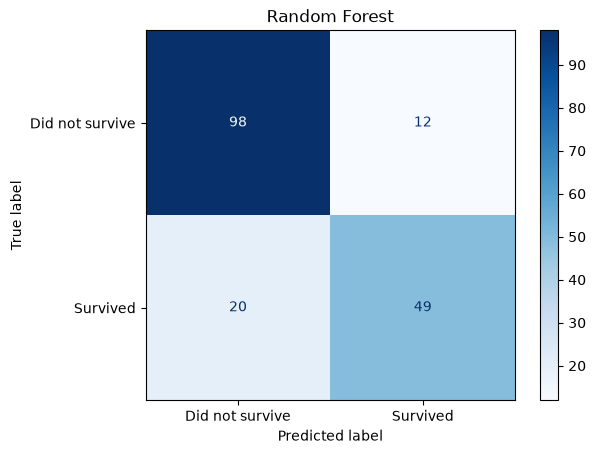

In [ ]:
best_name = comparison.iloc[0]["Model"]
best_cv_f1 = comparison.iloc[0]["F1"]

best_model = clone(models[best_name]).fit(X_train, y_train)
y_pred = best_model.predict(X_test)

test_scores = classification_scores(y_test, y_pred)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()

print(f"Best model: {best_name} | CV F1: {best_cv_f1:.4f}")
print(classification_report(y_test, y_pred, digits=4, zero_division=0))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=[0, 1],
    display_labels=["Did not survive", "Survived"], cmap="Blues"
)
plt.title(best_name)
plt.show()


## 10. Error Analysis
Xem tối đa 5 dự đoán sai cùng thông tin hành khách gốc.
Một dòng sai chỉ gợi ý giả thuyết, chưa đủ để kết luận nguyên nhân.
Sau khi chạy, ghi nhận các trường hợp có tuổi thiếu, hạng vé hoặc tổ hợp
đặc trưng mà model có thể chưa học tốt.


In [12]:
test_predictions = X.loc[X_test.index].assign(Actual=y_test, Predicted=y_pred)
errors = test_predictions.loc[test_predictions["Actual"] != test_predictions["Predicted"]].copy()
errors.insert(0, "Name", df.loc[errors.index, "Name"])
errors["Error type"] = np.where(errors["Predicted"] == 1, "False Positive", "False Negative")
error_examples = errors.head(5)

print("Incorrect predictions:", len(errors))
print(errors["Error type"].value_counts())
display(error_examples)


Incorrect predictions: 32
Error type
False Negative    20
False Positive    12
Name: count, dtype: int64


,Name,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Actual,Predicted,Error type
553,"Leeni, Mr. Fahim (""Philip Zenni"")",3,male,22.0,0,0,7.225,C,1,0,False Negative
559,"de Messemaeker, Mrs. Guillaume Joseph (Emma)",3,female,36.0,1,0,17.400,S,1,0,False Negative
536,"Butt, Major. Archibald Willingham",1,male,45.0,0,0,26.550,S,0,1,False Positive
27,"Fortune, Mr. Charles Alexander",1,male,19.0,3,2,263.000,S,0,1,False Positive
712,"Taylor, Mr. Elmer Zebley",1,male,48.0,1,0,52.000,S,1,0,False Negative


## 11. Model Interpretation
Nếu model tốt nhất là Random Forest, xem feature importance.
Nếu là model tuyến tính, xem hệ số: dấu dương làm tăng xu hướng dự đoán lớp `1`.
Cột số đã được standardize; cột phân loại đã được one-hot.

Importance/hệ số mô tả model, không chứng minh feature là nguyên nhân sống sót.
Các cột one-hot thuộc cùng một feature gốc; feature tương quan có thể chia sẻ ảnh hưởng.


Fare          0.256730
Age           0.243582
Sex_male      0.154490
Sex_female    0.131229
Pclass_3      0.048833
SibSp         0.045505
Parch         0.033632
Pclass_1      0.032193
Embarked_S    0.017988
Pclass_2      0.016983
dtype: float64

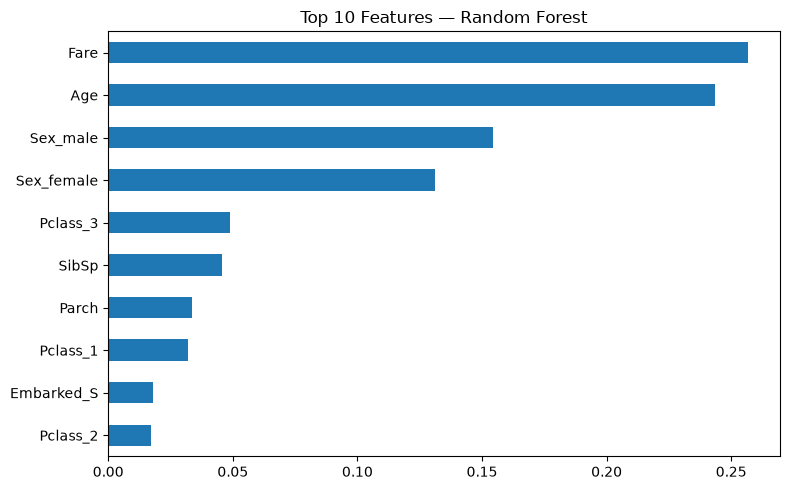

In [18]:
# Lấy Feature Importance hoặc Coefficient
values = (
    best_model.feature_importances_
    if hasattr(best_model, "feature_importances_")
    else best_model.coef_[0]
)

# Chọn 10 features quan trọng nhất
importance = pd.Series(values, index=X_train.columns)
top10 = importance.loc[importance.abs().nlargest(10).index]

# Hiển thị bảng và biểu đồ
display(top10)

top10.sort_values().plot.barh(
    figsize=(8, 5),
    title=f"Top 10 Features — {best_name}"
)

plt.tight_layout()
plt.show()

## 12. Improvement Suggestions
- Khắc phục data leakage: chia dữ liệu trước và học preprocessing riêng trong từng fold.
- Tuning trên Train/CV: `C` cho Logistic Regression/LinearSVC; `max_depth`,
  `min_samples_leaf` và `max_features` cho Random Forest.
- Feature engineering: `FamilySize = SibSp + Parch + 1`, `IsAlone`, danh xưng trong `Name`.
- So sánh imputation median chung với median theo nhóm phù hợp, học từ train mỗi fold.
- Kiểm tra độ ổn định bằng repeated CV; xem phân bố lỗi theo các nhóm hành khách.
- Nếu đổi model sau khi xem Test, cần một tập holdout mới để đánh giá khách quan.

Đây là hướng cải thiện, chưa được thực hiện trong baseline này.


## 13. Deployment and Engineering Thinking
Lưu cả model và thông số tiền xử lý; input mới phải dùng cùng danh sách features,
giá trị điền, cột encoding và scaler đã học. Không fit lại preprocessing trên input mới.

Ví dụ dưới đây tạo file `ex2_model.joblib` và thử dự đoán một hành khách.
Khi triển khai cần kiểm tra schema, giá trị hợp lệ, category mới, tỷ lệ missing,
phân bố dự đoán và chất lượng khi có nhãn thật. Chỉ nạp artifact từ nguồn tin cậy.


In [14]:
artifact_path = Path("ex2_model.joblib")
joblib.dump({
    "model": best_model, "model_name": best_name,
    "preprocessing": preprocessing_state, "features": features,
    "numerical_features": numerical_features, "categorical_features": categorical_features
}, artifact_path)

saved = joblib.load(artifact_path)
state = saved["preprocessing"]
new_passenger = pd.DataFrame([{
    "Pclass": 3, "Sex": "male", "Age": 22,
    "SibSp": 1, "Parch": 0, "Fare": 7.25, "Embarked": "S"
}])
new_input = new_passenger[saved["features"]].fillna(state["fill_values"])
new_input = new_input.astype({column: str for column in saved["categorical_features"]})
new_input = pd.get_dummies(new_input, columns=saved["categorical_features"], dtype=int)
new_input = new_input.reindex(columns=state["columns"], fill_value=0).astype(float)
new_input[saved["numerical_features"]] = state["scaler"].transform(new_input[saved["numerical_features"]])

print("Saved:", artifact_path)
print("New passenger prediction:", saved["model"].predict(new_input)[0])


Saved: ex2_model.joblib
New passenger prediction: 0


## 14. Final Submission Structure
Sau khi chạy notebook, các file gồm:
- `ex2.ipynb`: quy trình và kết quả thực hành.
- `README-ex2.md`: báo cáo được tạo từ metrics thực tế.
- `ex2_model.joblib`: model và thông số preprocessing.

README của project ở thư mục gốc vẫn là tài liệu giới thiệu project.


In [15]:
report = f"""# Titanic — ex2 report

## Method
Binary classification, stratified Train/Test 80/20, 5-fold CV on Train.
Missing values, encoding and scaling performed before splitting.
Selected model: {best_name}, chosen by mean CV F1={best_cv_f1:.4f}.

## Cross-validation
```text
{comparison.to_string(index=False, float_format='%.4f')}
```

## Test evaluation
```text
{classification_report(y_test, y_pred, digits=4, zero_division=0)}
```
TN={tn}, FP={fp}, FN={fn}, TP={tp}.
FP: predicted survival incorrectly. FN: predicted non-survival incorrectly.

## Error analysis
Incorrect predictions: {len(errors)}. Investigate missing age and similar passenger profiles;
these are hypotheses rather than proven causes.
```text
{error_examples.to_string()}
```

## Interpretation
{interpretation_label}; model influence does not establish causality.
```text
{interpretation[['Feature', 'Value']].head(10).to_string(index=False)}
```

## Limitations and improvements
Preprocessing before splitting causes data leakage; scores may be optimistic.
Small historical dataset, one split, no tuning; close CV scores may not imply a stable ranking.
Improve preprocessing inside folds, tuning and FamilySize/IsAlone/title features.

## Deployment and conclusion
ex2_model.joblib stores the model and preprocessing parameters.
Monitor input schema, missing values, unknown categories, drift and labeled metrics.
{best_name}: Test F1={test_scores['F1']:.4f}. This is a learning baseline.
"""
report_path = Path("README-ex2.md")
report_path.write_text(report, encoding="utf-8")
print("Report saved:", report_path)


Report saved: README-ex2.md


## 15. Minimum Practice Requirements
Kiểm tra kết quả chạy thay vì chỉ đếm cell.


In [16]:
requirements = {
    "At least 3 models, 5 folds each": len(cv_results) >= 3 and all(len(s["test_F1"]) == 5 for s in cv_results.values()),
    "CV metrics complete": all(np.isfinite(s[f"test_{m}"]).all() for s in cv_results.values() for m in scoring),
    "Test metrics complete": all(np.isfinite(v) for v in test_scores.values()),
    "No missing, matching columns": not X_train.isna().any().any() and not X_test.isna().any().any() and X_train.columns.equals(X_test.columns),
    "3–5 errors and interpretation": 3 <= len(error_examples) <= 5 and not interpretation.empty,
    "Model and report saved": artifact_path.exists() and report_path.exists(),
    "Limitations reported": "Limitations" in report
}
for name, passed in requirements.items():
    print(f"{'PASS' if passed else 'CHECK'}: {name}")


PASS: At least 3 models, 5 folds each
PASS: CV metrics complete
PASS: Test metrics complete
PASS: No missing, matching columns
PASS: 3–5 errors and interpretation
PASS: Model and report saved
PASS: Limitations reported


## 16. Conclusion Template
Kết luận dưới đây dùng kết quả thực tế. Bổ sung nhận xét cá nhân sau khi đọc
Confusion Matrix, các dự đoán sai và bảng interpretation.


In [17]:
print(f"Model tốt nhất theo CV: {best_name}; F1={best_cv_f1:.4f}.")
print(f"Test F1={test_scores['F1']:.4f}; FP={fp}, FN={fn}.")
print("Hạn chế: preprocessing trước split gây leakage; dữ liệu nhỏ, một lần chia, chưa tuning.")
print("Cải thiện: preprocessing trong từng fold, tuning và feature engineering.")


Model tốt nhất theo CV: Random Forest; F1=0.7311.
Test F1=0.7538; FP=12, FN=20.
Hạn chế: preprocessing trước split gây leakage; dữ liệu nhỏ, một lần chia, chưa tuning.
Cải thiện: preprocessing trong từng fold, tuning và feature engineering.
